In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

In [2]:
def convert_int_to_symbol(ls):
    """
    Convert, for example, 
    1) ['*', 'C', 'H', '2', '(', 'C', 'H', '2', ')', '3', 'O', 'H']  # list('*CH2(CH2)3OH')
        -> ['*', 'C', 'H', 'H', 'C', 'H', 'H', 'C', 'H', 'H', 'C', 'H', 'H', 'O', 'H']
    2) ['*', 'N', 'H', '+', '*', 'O', 'H']  # list('*NH+*OH')
        -> ['*', 'N', 'H', 'O', 'H']
    """
    try:
        parenthesis_left = ls.index('(')
        parenthesis_right = ls.index(')')
        len_par = parenthesis_right - parenthesis_left - 1
    except:
        pass
        
    converted_ls = []
    for i in range(len(ls)):
        try:
            multiple = int(ls[i])-1
            insert_elem = ls[i-1]
            if insert_elem != ')':
                for _ in range(multiple):
                    converted_ls.append(insert_elem)
            else:
                insert_elems = converted_ls[parenthesis_left:] #parenthesis_left+int(ls[i-2])+1
                for j in range(multiple):
                    for k in range(len(insert_elems)):
                        converted_ls.append(insert_elems[k])
        except:
            if ls[i] != '(' and ls[i] != ')':
                converted_ls.append(ls[i])
            
    _ls = [x for x in converted_ls if x != '-' and x != '+']
    value_to_unique = '*'
    result_list = [item for index, item in enumerate(_ls) \
                   if item != value_to_unique or index == _ls.index(item)]
    
    return result_list

def make_reaction(reactant, product):
    print(f'----- Entered -----')
    print(f' Reactant: {reactant}')
    print(f' Product: {product}')

    if '+' in reactant:
        idx = list(reactant).index('+')
        a = reactant[:idx]
        b = reactant[idx+1:]
        if '*' in a:
            reactant = a
        if '*' in b:
            reactant = b
        
    spl_reactant = convert_int_to_symbol(reactant)
    spl_product = convert_int_to_symbol(product)
    
    # Check if the form of input (reactant, product) is a list
    if type(reactant) != list:
        reactant = [reactant]
    if type(product) != list:
        product = [product]
        
    # Consideration of "*(:slab)" 
    if '*' not in list(reactant[0]):
        reactant.append('*')
    if '*' not in list(product[0]):
        product.append('*')
    
    # Adjust 'H2O' (product)
    count_spl_reactant = Counter(spl_reactant)
    count_spl_product = Counter(spl_product)
    O_number = count_spl_reactant['O'] - count_spl_product['O']
    if O_number != 0:
        h2o_adj = f"(H2O){O_number}"
        spl_h2o_adj = convert_int_to_symbol(list(h2o_adj))
        if O_number == 1:
            product.append('H2O')    
        else:
            product.append(f'{O_number}H2O')
        spl_product.extend(spl_h2o_adj)
    count_spl_product = Counter(spl_product)
    
    # Adjust 'H' (reactant)
    H_number = count_spl_product['H'] - count_spl_reactant['H']
    if H_number != 0:
        h_adj = f"(H){H_number}"
        spl_h_adj = convert_int_to_symbol(list(h_adj))
        if H_number == 1:
            reactant.append('H')    
        else:
            reactant.append(f'{H_number}H')
        spl_reactant.extend(spl_h_adj)
        step = H_number
    else:  # H_number == 0:
        step = 0

    if '+' in product[0]:
        print(product)
        idx = list(product[0]).index('+')
        a = product[0][:idx]
        b = product[0][idx+1:]
        del product[0]
        product.extend([a, b])
        print(product)
    
    print(f'\033[32m----- Result  -----')
    print(f' Reaction: {reactant} -> {product}\033[0m')
    
    return reactant, product, step

def calculate_relative_quantity(reactant, product, file_path, sheet_name=0, quantity='G'):
    Q_reactant = 0
    Q_product = 0
    data = pd.read_excel(file_path, sheet_name)
    columns = data.columns
    target_column = quantity
    column_index = list(columns).index(target_column)
    
    if 'H' in reactant[-1] and reactant[-1][0] != 'H' and len(reactant) != 1:
        number = int(reactant[-1][0])
        symbol = reactant[-1][1:]
        del reactant[-1]
        for i in range(number):
            reactant.append(symbol)
        
    if 'H2O' in product[-1] and product[-1][0] != 'H' and len(list(product[-1])) == 3:
        number = int(product[-1][0])
        symbol = product[-1][1:]
        del product[-1]
        for i in range(number):
            product.append(symbol)

    for symbol in reactant:
        row_index = data.index[data['Symbols'] == symbol][0] 
        Q_reactant += data.iloc[row_index, column_index]
    for symbol in product:
        row_index = data.index[data['Symbols'] == symbol][0]
        Q_product += data.iloc[row_index, column_index]
        
    return Q_reactant, Q_product

def RT_to_eV(T):
    R = 8.31446261815324 # J/K mol
    Na = 6.02214076*(10**23)
    eV_mol = R*T / (1.602176633999*(10**(-19)))
    eV = eV_mol / Na
    return eV

def plot_relative_physical_quantity(file_path='energies.xlsx',
                                    sheet_name=['Sheet1'],
                                    U=0.0,
                                    color=None,
                                    figure_size=None,
                                    reactions=None,
                                    spanned_num=5,
                                    quantity='G',
                                    correction=0.0):
    """
    1) file_path: str 
        path of xlsx file about Gibbs energy
    2) sheet_name: list of str
        sheet name of xlsx file
    3) U: float
        applied electrode potential
    4) color: list of str
        list of colors for plotting
    5) figure_size: list of int
        list of x and y coordinates
    6) reactions: dictionary of str 
        dictionary of reaction pathways
    7) spanned_num: int
        adjusting the factor of the bar's width of the graph
    8) quantity: str
        quantity to plot (ex: 'G' or 'E(DFT)')
    9) correction: float
        value of correction (unit: eV)
    """
    if figure_size != None:
        x_axis = figure_size[0]
        y_axis = figure_size[1]
        plt.figure(figsize=(x_axis, y_axis))

    print(f'\n** correctoin = {correction} eV **')
        
    for k in range(len(reactions)):
        key = list(reactions.keys())[k]
        delta_Q = [0]
        print(f'\n============= {key} =============')
        path_symbols = reactions[key]
        
        cum_step = 0
        xticks_labels = [cum_step]
        for i in range(len(path_symbols)-1):
            print(f'\n STEP {i+1}')
            reactant, product, step = make_reaction(path_symbols[i], path_symbols[i+1])
            Q_reactant, Q_product = calculate_relative_quantity(reactant, 
                                                                product, 
                                                                file_path, 
                                                                sheet_name[k],
                                                                quantity)
            dE = [Q_product - Q_reactant + U*step + correction*step] 
            delta_Q += dE
            print(f' \033[34m=> \u0394{quantity} = {dE[0]:5.5f} eV\033[0m')
            
            cum_step += step
            xticks_labels.append(f'{cum_step}')
    
        cumsum_E = np.cumsum(delta_Q)
        spanned_enes = [e for e in cumsum_E for _ in range(spanned_num)]  
        sub_enes = [spanned_enes[i+1]-spanned_enes[i] for i in range(len(spanned_enes[:-1]))]
        
        xticks_positions = []
        for i in range(len(reactions[key])):
            xticks_positions.append(spanned_num*i+2)
        maximum = max(delta_Q[1:])
        max_index = delta_Q.index(maximum)
        #print(f'\n \033[31m==> Negative limiting potential = {maximum:5.5f} eV\033[0m : STEP {max_index}\n')
        print(f'\n \033[31m==> \u0394{quantity} of rate-determining step = {maximum:5.5f} eV\033[0m : STEP {max_index}\n')
        x = np.arange(0, len(spanned_enes), 1)
        plt.plot(x, spanned_enes, color = color[k], label=f'{key}', alpha = 1)
        plt.xticks(xticks_positions, xticks_labels, fontsize=12)
        plt.yticks(fontsize=12)
        #plt.ylabel(f'$\u0394{quantity}$ $(eV)$ at {U} V (vs. RHE)', fontsize=13)
        plt.ylabel(f'$\u0394{quantity}$ $(eV)$', fontsize=13)
        plt.xlabel(r'($H^+$ + $e^-$)' + ' transferred', fontsize=13)
        plt.legend(loc='upper right', fontsize=12)

    #return x, spanned_enes, xticks_positions, xticks_labels


In [3]:
file_path = '../Data/NRR_on_AlFe.xlsx'

## Figure S9, pure Al(111)


** correctoin = -1.479 eV **

============= N-end =============

 STEP 1
----- Entered -----
 Reactant: HNO3
 Product: *N*OO
----- Result  -----
 Reaction: ['HNO3', '*', 'H'] -> ['*N*OO', 'H2O']
 => ΔG = -3.99044 eV

 STEP 2
----- Entered -----
 Reactant: *N*OO
 Product: *NO2H
----- Result  -----
 Reaction: ['*N*OO', 'H'] -> ['*NO2H']
 => ΔG = -0.46984 eV

 STEP 3
----- Entered -----
 Reactant: *NO2H
 Product: *NO
----- Result  -----
 Reaction: ['*NO2H', 'H'] -> ['*NO', 'H2O']
 => ΔG = -3.47792 eV

 STEP 4
----- Entered -----
 Reactant: *NO
 Product: *NOH
----- Result  -----
 Reaction: ['*NO', 'H'] -> ['*NOH']
 => ΔG = -1.93564 eV

 STEP 5
----- Entered -----
 Reactant: *NOH
 Product: *N
----- Result  -----
 Reaction: ['*NOH', 'H'] -> ['*N', 'H2O']
 => ΔG = -3.62400 eV

 STEP 6
----- Entered -----
 Reactant: *N
 Product: *NH
----- Result  -----
 Reaction: ['*N', 'H'] -> ['*NH']
 => ΔG = -1.72465 eV

 STEP 7
----- Entered -----
 Reactant: *NH
 Product: *NH2
----- Result  -----
 Reactio

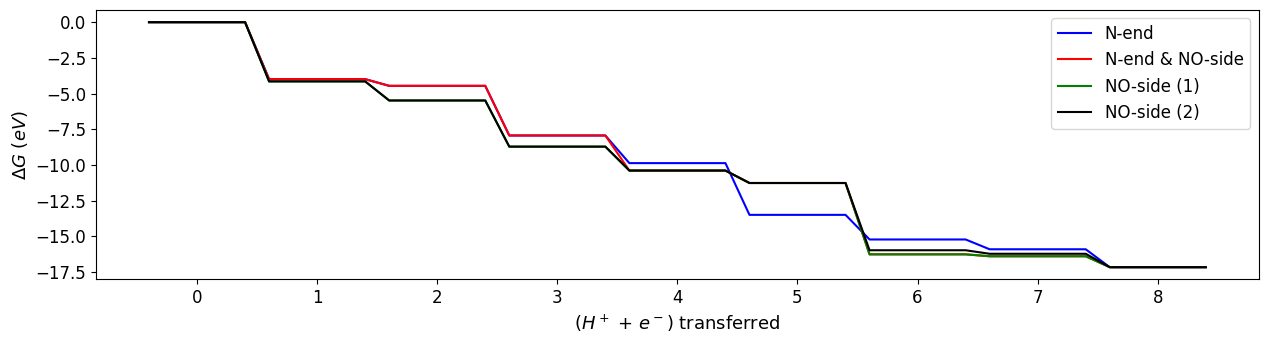

In [4]:
reactions = {
    'N-end' : ['HNO3', '*N*OO', '*NO2H', '*NO', '*NOH', '*N', '*NH', '*NH2', 'NH3'],
    'N-end & NO-side' : ['HNO3', '*N*OO', '*NO2H', '*NO', '*O*NH', '*O*NH2', '*O-1+NH3', '*OH-1', 'H2O'],
    'NO-side (1)' : ['HNO3', 'N*O2', '*N*OOH', '*O*N', '*O*NH', '*O*NH2', '*O-1+NH3', '*OH-1', 'H2O'],
    'NO-side (2)' : ['HNO3', 'N*O2', '*N*OOH', '*O*N', '*O*NH', '*O*NH2', '*O-2+NH3', '*OH-2', 'H2O'],
}
plot_relative_physical_quantity(file_path=file_path,
                                sheet_name=['Al', 'Al', 'Al', 'Al'],
                                U=0.0,
                                color=['b', 'r', 'green', 'black'],
                                figure_size=[15, 3.5],
                                reactions=reactions,
                                spanned_num=5,
                                quantity='G',
                                correction=-1.479)

## Figure S10, Fe1Al


** correctoin = -1.479 eV **

============= N-end =============

 STEP 1
----- Entered -----
 Reactant: HNO3
 Product: *N*OO
----- Result  -----
 Reaction: ['HNO3', '*', 'H'] -> ['*N*OO', 'H2O']
 => ΔG = -4.17069 eV

 STEP 2
----- Entered -----
 Reactant: *N*OO
 Product: *NO-*OH
----- Result  -----
 Reaction: ['*N*OO', 'H'] -> ['*NO-*OH']
 => ΔG = -3.47957 eV

 STEP 3
----- Entered -----
 Reactant: *NO-*OH
 Product: *NO
----- Result  -----
 Reaction: ['*NO-*OH', 'H'] -> ['*NO', 'H2O']
 => ΔG = -0.57868 eV

 STEP 4
----- Entered -----
 Reactant: *NO
 Product: *NH-*O
----- Result  -----
 Reaction: ['*NO', 'H'] -> ['*NH-*O']
 => ΔG = -5.41636 eV

 STEP 5
----- Entered -----
 Reactant: *NH-*O
 Product: *NH-*OH
----- Result  -----
 Reaction: ['*NH-*O', 'H'] -> ['*NH-*OH']
 => ΔG = -0.44394 eV

 STEP 6
----- Entered -----
 Reactant: *NH-*OH
 Product: *NH
----- Result  -----
 Reaction: ['*NH-*OH', 'H'] -> ['*NH', 'H2O']
 => ΔG = -0.71977 eV

 STEP 7
----- Entered -----
 Reactant: *NH
 Produc

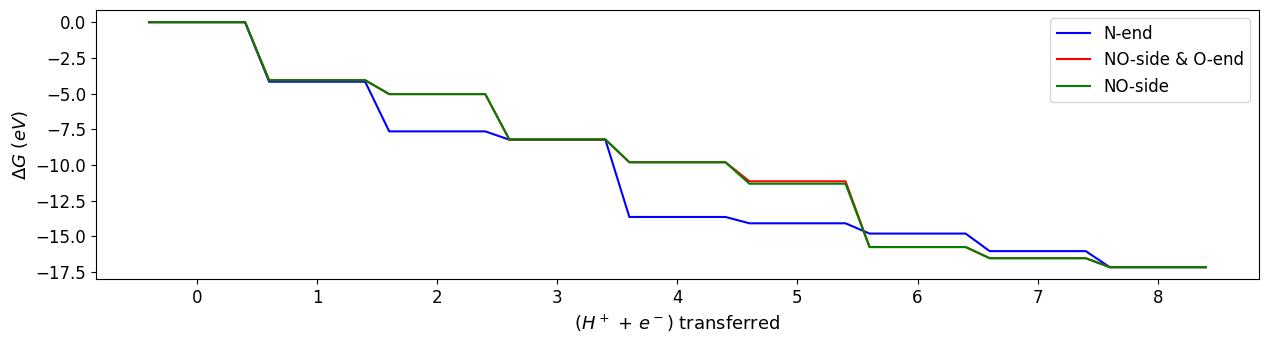

In [5]:
reactions = {
     'N-end': ['HNO3', '*N*OO', '*NO-*OH', '*NO', '*NH-*O', '*NH-*OH', '*NH', '*NH2', 'NH3'],
     'NO-side & O-end' : ['HNO3', 'N*O2', '*N*OOH', '*O*N', '*O*NH', '*ONH2', '*O+NH3', '*OH', 'H2O'],
     'NO-side' : ['HNO3', 'N*O2', '*N*OOH', '*O*N', '*O*NH', '*O*NH2', '*O+NH3', '*OH', 'H2O'],
}
plot_relative_physical_quantity(file_path=file_path,
                                sheet_name=['FeAl', 'FeAl', 'FeAl'],
                                U=0.0,
                                color=['b', 'r', 'green'],
                                figure_size=[15, 3.5],
                                reactions=reactions,
                                spanned_num=5,
                                quantity='G',
                                correction=-1.479)

## Figure S11, Fe2Al


** correctoin = -1.479 eV **

============= NO-side =============

 STEP 1
----- Entered -----
 Reactant: HNO3
 Product: N*O2-1
----- Result  -----
 Reaction: ['HNO3', '*', 'H'] -> ['N*O2-1', 'H2O']
 => ΔG = -3.61445 eV

 STEP 2
----- Entered -----
 Reactant: N*O2-1
 Product: *N*OOH
----- Result  -----
 Reaction: ['N*O2-1', 'H'] -> ['*N*OOH']
 => ΔG = -1.33820 eV

 STEP 3
----- Entered -----
 Reactant: *N*OOH
 Product: *O*N
----- Result  -----
 Reaction: ['*N*OOH', 'H'] -> ['*O*N', 'H2O']
 => ΔG = -3.26693 eV

 STEP 4
----- Entered -----
 Reactant: *O*N
 Product: *O*NH
----- Result  -----
 Reaction: ['*O*N', 'H'] -> ['*O*NH']
 => ΔG = -1.51589 eV

 STEP 5
----- Entered -----
 Reactant: *O*NH
 Product: *O*NH2
----- Result  -----
 Reaction: ['*O*NH', 'H'] -> ['*O*NH2']
 => ΔG = -2.01032 eV

 STEP 6
----- Entered -----
 Reactant: *O*NH2
 Product: *O-1+NH3
['*O-1+NH3']
['*O-1', 'NH3']
----- Result  -----
 Reaction: ['*O*NH2', 'H'] -> ['*O-1', 'NH3']
 => ΔG = -3.99516 eV

 STEP 7
----- Ent

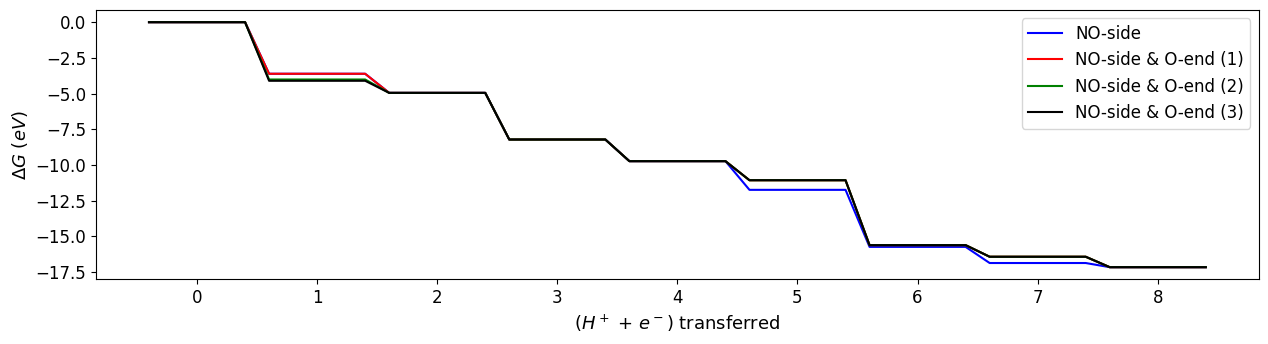

In [6]:
reactions = {
    'NO-side' : ['HNO3', 'N*O2-1', '*N*OOH', '*O*N', '*O*NH', '*O*NH2', '*O-1+NH3', '*OH-1', 'H2O'],
    'NO-side & O-end (1)' : ['HNO3', 'N*O2-1', '*N*OOH', '*O*N', '*O*NH', '*ONH2', '*O-2+NH3', '*OH-2', 'H2O'],
    'NO-side & O-end (2)' : ['HNO3', 'N*O2-2', '*N*OOH', '*O*N', '*O*NH', '*ONH2', '*O-2+NH3', '*OH-2', 'H2O'],
    'NO-side & O-end (3)' : ['HNO3', 'N*O2-3', '*N*OOH', '*O*N', '*O*NH', '*ONH2', '*O-2+NH3', '*OH-2', 'H2O'],
}
plot_relative_physical_quantity(file_path=file_path,
                                sheet_name=['Fe2Al', 'Fe2Al', 'Fe2Al', 'Fe2Al'],
                                U=0.0,
                                color=['b', 'r', 'green', 'black'],
                                figure_size=[15, 3.5],
                                reactions=reactions,
                                spanned_num=5,
                                quantity='G',
                                correction=-1.479)

## Figure S12, Fe3Al


** correctoin = -1.479 eV **

============= NO-side =============

 STEP 1
----- Entered -----
 Reactant: HNO3
 Product: N*O2-1
----- Result  -----
 Reaction: ['HNO3', '*', 'H'] -> ['N*O2-1', 'H2O']
 => ΔG = -3.89472 eV

 STEP 2
----- Entered -----
 Reactant: N*O2-1
 Product: *N*OOH
----- Result  -----
 Reaction: ['N*O2-1', 'H'] -> ['*N*OOH']
 => ΔG = -1.24914 eV

 STEP 3
----- Entered -----
 Reactant: *N*OOH
 Product: *O*N
----- Result  -----
 Reaction: ['*N*OOH', 'H'] -> ['*O*N', 'H2O']
 => ΔG = -3.09334 eV

 STEP 4
----- Entered -----
 Reactant: *O*N
 Product: *O*NH
----- Result  -----
 Reaction: ['*O*N', 'H'] -> ['*O*NH']
 => ΔG = -1.71711 eV

 STEP 5
----- Entered -----
 Reactant: *O*NH
 Product: *O*NH2
----- Result  -----
 Reaction: ['*O*NH', 'H'] -> ['*O*NH2']
 => ΔG = -1.84105 eV

 STEP 6
----- Entered -----
 Reactant: *O*NH2
 Product: *O-1+NH3
['*O-1+NH3']
['*O-1', 'NH3']
----- Result  -----
 Reaction: ['*O*NH2', 'H'] -> ['*O-1', 'NH3']
 => ΔG = -4.37435 eV

 STEP 7
----- Ent

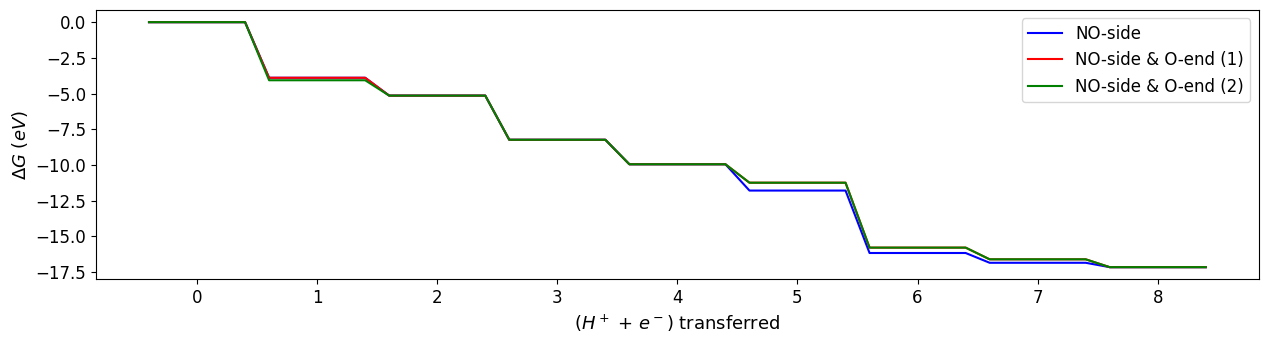

In [7]:
reactions = {
    'NO-side' : ['HNO3', 'N*O2-1', '*N*OOH', '*O*N', '*O*NH', '*O*NH2', '*O-1+NH3', '*OH-1', 'H2O'],
    'NO-side & O-end (1)' : ['HNO3', 'N*O2-1', '*N*OOH', '*O*N', '*O*NH', '*ONH2', '*O-2+NH3', '*OH-2', 'H2O'],
    'NO-side & O-end (2)' : ['HNO3', 'N*O2-2', '*N*OOH', '*O*N', '*O*NH', '*ONH2', '*O-2+NH3', '*OH-2', 'H2O'],
}
plot_relative_physical_quantity(file_path=file_path,
                                sheet_name=['Fe3Al', 'Fe3Al', 'Fe3Al', 'Fe3Al'],
                                U=0.0,
                                color=['b', 'r', 'green', 'black'],
                                figure_size=[15, 3.5],
                                reactions=reactions,
                                spanned_num=5,
                                quantity='G',
                                correction=-1.479)

## Figure S13


** correctoin = -1.479 eV **

============= Al =============

 STEP 1
----- Entered -----
 Reactant: HNO3
 Product: N*O2
----- Result  -----
 Reaction: ['HNO3', '*', 'H'] -> ['N*O2', 'H2O']
 => ΔG = -4.14845 eV

 STEP 2
----- Entered -----
 Reactant: N*O2
 Product: *N*OOH
----- Result  -----
 Reaction: ['N*O2', 'H'] -> ['*N*OOH']
 => ΔG = -1.33764 eV

 STEP 3
----- Entered -----
 Reactant: *N*OOH
 Product: *O*N
----- Result  -----
 Reaction: ['*N*OOH', 'H'] -> ['*O*N', 'H2O']
 => ΔG = -3.23203 eV

 STEP 4
----- Entered -----
 Reactant: *O*N
 Product: *O*NH
----- Result  -----
 Reaction: ['*O*N', 'H'] -> ['*O*NH']
 => ΔG = -1.67637 eV

 STEP 5
----- Entered -----
 Reactant: *O*NH
 Product: *O*NH2
----- Result  -----
 Reaction: ['*O*NH', 'H'] -> ['*O*NH2']
 => ΔG = -0.87206 eV

 STEP 6
----- Entered -----
 Reactant: *O*NH2
 Product: *O-1+NH3
['*O-1+NH3']
['*O-1', 'NH3']
----- Result  -----
 Reaction: ['*O*NH2', 'H'] -> ['*O-1', 'NH3']
 => ΔG = -4.99776 eV

 STEP 7
----- Entered -----
 R

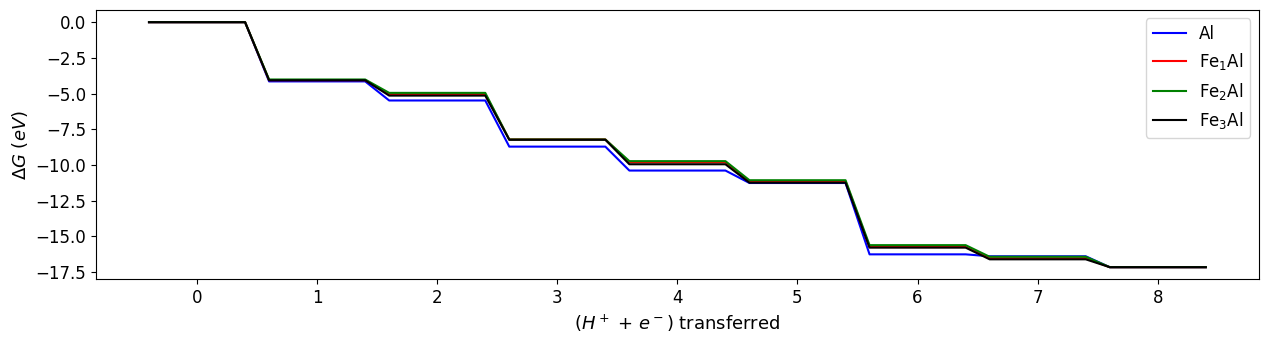

In [8]:
reactions = {
             'Al' : ['HNO3', 'N*O2', '*N*OOH', '*O*N', '*O*NH', '*O*NH2', '*O-1+NH3', '*OH-1', 'H2O'],
             r'Fe$_1$Al' : ['HNO3', 'N*O2', '*N*OOH', '*O*N', '*O*NH', '*ONH2', '*O+NH3', '*OH', 'H2O'],
             r'Fe$_2$Al' : ['HNO3', 'N*O2-2', '*N*OOH', '*O*N', '*O*NH', '*ONH2', '*O-2+NH3', '*OH-2', 'H2O'],
             r'Fe$_3$Al' : ['HNO3', 'N*O2-2', '*N*OOH', '*O*N', '*O*NH', '*ONH2', '*O-2+NH3', '*OH-2', 'H2O'],        
}

plot_relative_physical_quantity(file_path=file_path,
                                sheet_name=['Al', 'FeAl', 'Fe2Al', 'Fe3Al'],
                                U=0.0,
                                color=['b', 'r', 'green', 'black'],
                                figure_size=[15, 3.5],
                                reactions=reactions,
                                spanned_num=5,
                                quantity='G',
                                correction=-1.479)

## Figure 4


** correctoin = -1.479 eV **

============= Al =============

 STEP 1
----- Entered -----
 Reactant: HNO3
 Product: *N*OO
----- Result  -----
 Reaction: ['HNO3', '*', 'H'] -> ['*N*OO', 'H2O']
 => ΔG = -3.99044 eV

 STEP 2
----- Entered -----
 Reactant: *N*OO
 Product: *NO2H
----- Result  -----
 Reaction: ['*N*OO', 'H'] -> ['*NO2H']
 => ΔG = -0.46984 eV

 STEP 3
----- Entered -----
 Reactant: *NO2H
 Product: *NO
----- Result  -----
 Reaction: ['*NO2H', 'H'] -> ['*NO', 'H2O']
 => ΔG = -3.47792 eV

 STEP 4
----- Entered -----
 Reactant: *NO
 Product: *NOH
----- Result  -----
 Reaction: ['*NO', 'H'] -> ['*NOH']
 => ΔG = -1.93564 eV

 STEP 5
----- Entered -----
 Reactant: *NOH
 Product: *N
----- Result  -----
 Reaction: ['*NOH', 'H'] -> ['*N', 'H2O']
 => ΔG = -3.62400 eV

 STEP 6
----- Entered -----
 Reactant: *N
 Product: *NH
----- Result  -----
 Reaction: ['*N', 'H'] -> ['*NH']
 => ΔG = -1.72465 eV

 STEP 7
----- Entered -----
 Reactant: *NH
 Product: *NH2
----- Result  -----
 Reaction: 

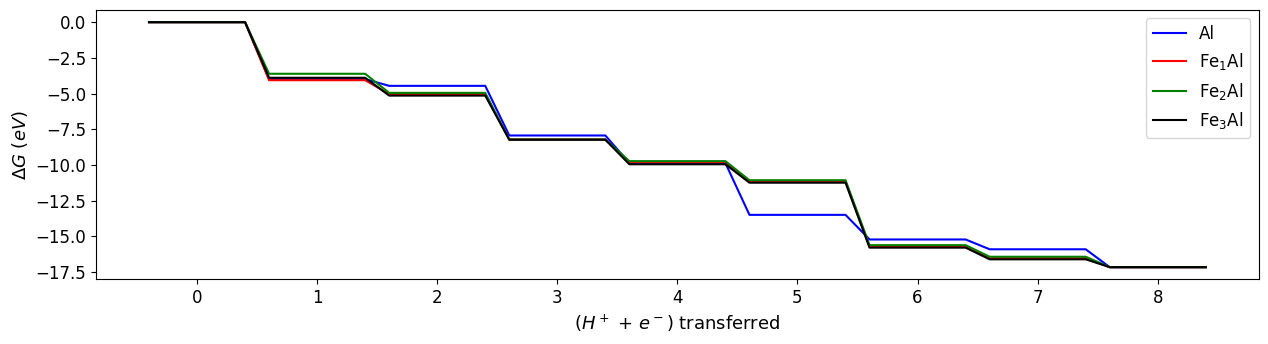

In [9]:
reactions = {
             'Al' : ['HNO3', '*N*OO', '*NO2H', '*NO', '*NOH', '*N', '*NH', '*NH2', 'NH3'],
             r'Fe$_1$Al' : ['HNO3', 'N*O2', '*N*OOH', '*O*N', '*O*NH', '*ONH2', '*O+NH3', '*OH', 'H2O'],
             r'Fe$_2$Al' : ['HNO3', 'N*O2-1', '*N*OOH', '*O*N', '*O*NH', '*ONH2', '*O-2+NH3', '*OH-2', 'H2O'],
             r'Fe$_3$Al' : ['HNO3', 'N*O2-1', '*N*OOH', '*O*N', '*O*NH', '*ONH2', '*O-2+NH3', '*OH-2', 'H2O'],      
}

plot_relative_physical_quantity(file_path=file_path,
                                sheet_name=['Al', 'FeAl', 'Fe2Al', 'Fe3Al'],
                                U=0.0,
                                color=['b', 'r', 'green', 'black'],
                                figure_size=[15, 3.5],
                                reactions=reactions,
                                spanned_num=5,
                                quantity='G',
                                correction=-1.479)